Завантаження та нормалізація даних MNIST

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras.models import Sequential, load_model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input
from keras import utils
from keras.utils import to_categorical, load_img, img_to_array
from sklearn.model_selection import KFold

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train_norm = X_train / 255.0
X_test_norm = X_test / 255.0

print(f"Розмірність навчальних даних: {X_train.shape}")
print(f"Розмірність тестових даних: {X_test.shape}")


Розмірність навчальних даних: (60000, 28, 28)
Розмірність тестових даних: (10000, 28, 28)


Клас Callback та навчання моделі до 99% точності

In [5]:
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.99:
            print("\nReached 99% accuracy so cancelling training!")
            print(f"Досягнуто 99% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

def train_mnist(x_train, y_train):
    callbacks = myCallback()
    
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    history = model.fit(x_train, y_train, epochs=10, callbacks=[callbacks], verbose=1)
    return history

hist = train_mnist(X_train_norm, y_train)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9410 - loss: 0.2008
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9758 - loss: 0.0791
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9841 - loss: 0.0515
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9879 - loss: 0.0373
Epoch 5/10
1869/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9915 - loss: 0.0265
Reached 99% accuracy so cancelling training!
Досягнуто 99% точності на епосі 5, тому скасовуємо навчання!
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9915 - loss: 0.0265


Візуалізація перших 4 зображень

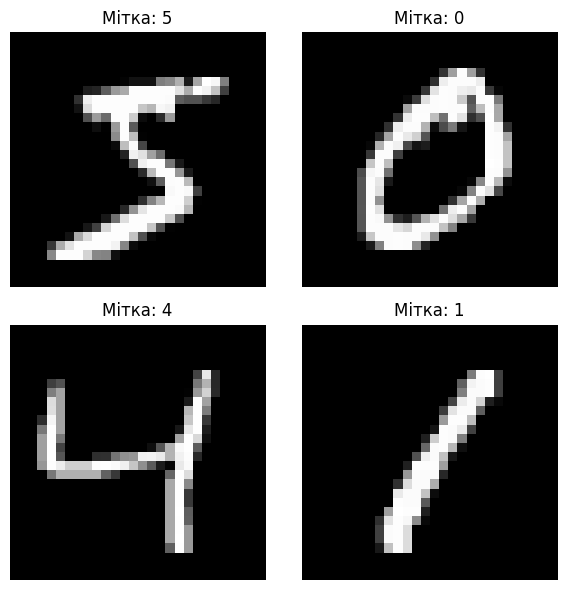

In [6]:
plt.figure(figsize=(6, 6))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Мітка: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# ============================================================
# ЗАВДАННЯ 5.1: Кастомний зворотний виклик (Callback) у Keras
# ============================================================
# Мета: припинити тренування моделі, коли досягнуто 99% точності
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        # Перевірка досягнення порогу точності 99%
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.99:
            print("\nReached 99% accuracy so cancelling training!")
            print(f"Досягнуто 99% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

# Окрема функція для створення та тренування моделі Завдання 1
def train_mnist(x_train, y_train):
    callbacks = myCallback() # Екземпляр кастомного зворотного виклику
    
    # Архітектура моделі: вирівнювання 28x28 + повнозв'язний шар + 10 виходів Softmax
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    # Тренування моделі із передачею callback
    history = model.fit(x_train, y_train, epochs=10, callbacks=[callbacks], verbose=1)
    return history

# Запуск тренування для Завдання 1
hist = train_mnist(X_train_norm, y_train)
